In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the Titanic dataset directly
df = sns.load_dataset('titanic')

# View the first 5 rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Question 1: What was the overall survival rate of passengers?

Question 2: Did gender or passenger class (pclass) impact survival chances?

Question 3: Are there extreme outliers in ticket prices (fare) or passenger ages?

In [2]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names and data types (integers, floats, objects)
print("\nData Types and Info:")
df.info()

# View statistical summary (mean, median, min, max)
df.describe()

Dataset Shape: (891, 15)

Data Types and Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [3]:
# 1. Check for missing values in each column
print("Missing Values:\n", df.isnull().sum())

# 2. Check for duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 3. Clean the data: Fill missing 'age' with the median age, and drop 'deck' (too many missing values)
df['age'] = df['age'].fillna(df['age'].median())
df = df.drop(columns=['deck'])

# Remove duplicate rows if any exist
df = df.drop_duplicates()

print("\nMissing values after cleaning:\n", df.isnull().sum())

Missing Values:
 survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Duplicate Rows: 107

Missing values after cleaning:
 survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       2
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


Survival Rate by Gender:
 sex
female    73.972603
male      21.532091
Name: survived, dtype: float64

Survival Rate by Passenger Class:
 pclass
1    63.333333
2    50.609756
3    25.935162
Name: survived, dtype: float64


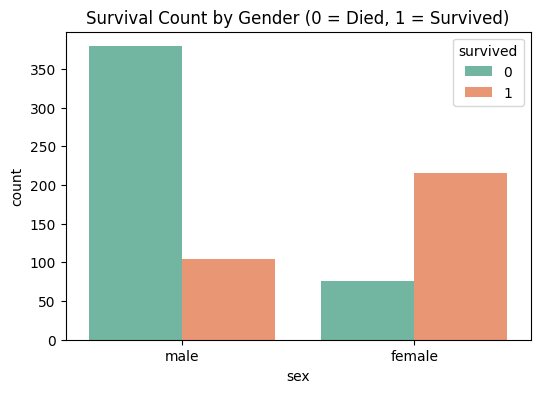

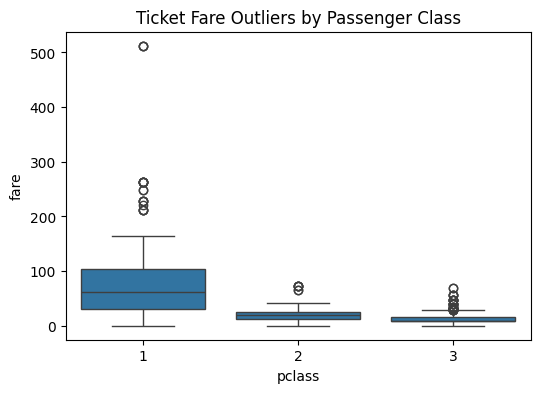

In [4]:
# Pattern 1: Survival rate by Gender and Class (Statistics)
print("Survival Rate by Gender:\n", df.groupby('sex')['survived'].mean() * 100)
print("\nSurvival Rate by Passenger Class:\n", df.groupby('pclass')['survived'].mean() * 100)

# Visualization 1: Survival count by Gender
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='sex', hue='survived', palette='Set2')
plt.title('Survival Count by Gender (0 = Died, 1 = Survived)')
plt.show()

# Visualization 2: Boxplot to detect anomalies/outliers in Fare across classes
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='pclass', y='fare')
plt.title('Ticket Fare Outliers by Passenger Class')
plt.show()

Key Insights & Conclusion:

Insight 1: Females had a much higher survival rate (~74%) compared to males (~19%).

Insight 2: 1st-class passengers had the highest survival rate (~63%), while 3rd-class had the lowest (~24%).

Data Issues Fixed: Missing age values were imputed using the median, the mostly empty deck column was dropped, and duplicate entries were removed.